In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display
import matplotlib.pyplot as plt

simulator = AerSimulator()
shots = 100

print("Qiskit Fall Fest 2026")
print("Challenge 3: Can You Change the Correlation?")
print("Simulator initialized successfully!")

Qiskit Fall Fest 2026
Challenge 3: Can You Change the Correlation?
Simulator initialized successfully!


In [2]:
predictions = {
    "Original Bell Circuit": {
        "00": 50,
        "01": 0,
        "10": 0,
        "11": 50
    },
    "Modified Bell Circuit": {
        "00": 0,
        "01": 50,
        "10": 50,
        "11": 0
    }
}

print("PREDICTIONS BEFORE EXECUTION")
print("=" * 60)

for name, prediction in predictions.items():
    print(f"\n{name}")
    for state, count in prediction.items():
        print(f"  {state}: {count}%")

PREDICTIONS BEFORE EXECUTION

Original Bell Circuit
  00: 50%
  01: 0%
  10: 0%
  11: 50%

Modified Bell Circuit
  00: 0%
  01: 50%
  10: 50%
  11: 0%


Original Bell-State Circuit


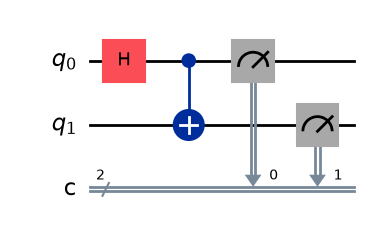

In [3]:
original_circuit = QuantumCircuit(2, 2)

original_circuit.h(0)
original_circuit.cx(0, 1)

original_circuit.measure([0, 1], [0, 1])

print("Original Bell-State Circuit")
display(original_circuit.draw("mpl"))

Modified Bell-State Circuit


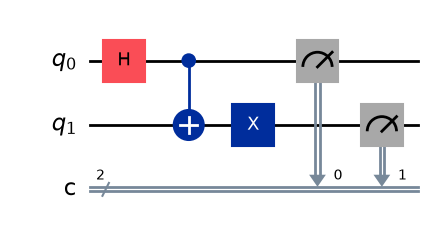

In [4]:
modified_circuit = QuantumCircuit(2, 2)

modified_circuit.h(0)
modified_circuit.cx(0, 1)

# Added gate to change the correlation
modified_circuit.x(1)

modified_circuit.measure([0, 1], [0, 1])

print("Modified Bell-State Circuit")
display(modified_circuit.draw("mpl"))

In [5]:
circuits = {
    "Original Bell Circuit": original_circuit,
    "Modified Bell Circuit": modified_circuit
}

results = {}

for name, circuit in circuits.items():

    compiled = transpile(circuit, simulator)

    job = simulator.run(compiled, shots=shots)

    counts = job.result().get_counts()

    results[name] = counts

    print(f"{name}: {counts}")

print("\nBoth circuits executed successfully!")

Original Bell Circuit: {'00': 53, '11': 47}
Modified Bell Circuit: {'10': 56, '01': 44}

Both circuits executed successfully!


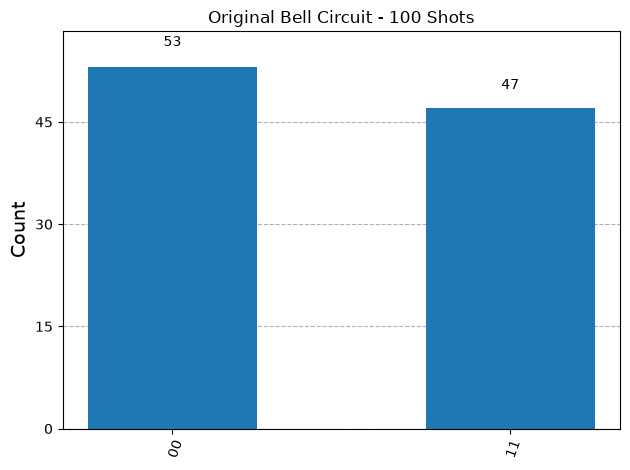

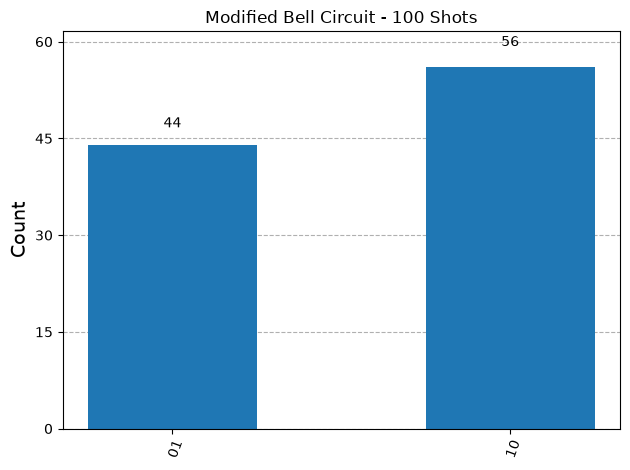

In [6]:
for name, counts in results.items():

    display(
        plot_histogram(
            counts,
            title=f"{name} - 100 Shots",
            bar_labels=True
        )
    )

In [7]:
print("PREDICTION VS ACTUAL RESULTS")
print("=" * 85)

print(
    f"{'Circuit':<25}"
    f"{'State':<10}"
    f"{'Predicted':<15}"
    f"{'Actual':<15}"
)

print("-" * 85)

for name in circuits:

    for state in ["00", "01", "10", "11"]:

        predicted = predictions[name][state]
        actual = results[name].get(state, 0)

        print(
            f"{name:<25}"
            f"{state:<10}"
            f"{predicted:<15}"
            f"{actual:<15}"
        )

    print("-" * 85)

PREDICTION VS ACTUAL RESULTS
Circuit                  State     Predicted      Actual         
-------------------------------------------------------------------------------------
Original Bell Circuit    00        50             53             
Original Bell Circuit    01        0              0              
Original Bell Circuit    10        0              0              
Original Bell Circuit    11        50             47             
-------------------------------------------------------------------------------------
Modified Bell Circuit    00        0              0              
Modified Bell Circuit    01        50             44             
Modified Bell Circuit    10        50             56             
Modified Bell Circuit    11        0              0              
-------------------------------------------------------------------------------------


In [8]:
print("QUANTUM CORRELATION ANALYSIS")
print("=" * 60)

for name, counts in results.items():

    same = counts.get("00", 0) + counts.get("11", 0)
    opposite = counts.get("01", 0) + counts.get("10", 0)

    print(f"\n{name}")
    print(f"Same outcomes     : {same}%")
    print(f"Opposite outcomes : {opposite}%")

    if same > opposite:
        print("Observation: Positive correlation")
    elif opposite > same:
        print("Observation: Negative correlation")
    else:
        print("Observation: No net correlation")

QUANTUM CORRELATION ANALYSIS

Original Bell Circuit
Same outcomes     : 100%
Opposite outcomes : 0%
Observation: Positive correlation

Modified Bell Circuit
Same outcomes     : 0%
Opposite outcomes : 100%
Observation: Negative correlation


In [9]:
print("CHALLENGE 3 VALIDATION")
print("=" * 60)

for name, circuit in circuits.items():

    assert circuit.num_qubits == 2
    assert circuit.num_clbits == 2

    operations = circuit.count_ops()

    assert operations.get("measure", 0) == 2

    gate_count = sum(
        count for gate, count in operations.items()
        if gate != "measure"
    )

    assert gate_count <= 4
    assert sum(results[name].values()) == 100

    print(f"PASS: {name}")

# Verify exactly one additional X gate
original_ops = original_circuit.count_ops()
modified_ops = modified_circuit.count_ops()

assert original_ops.get("h", 0) == 1
assert original_ops.get("cx", 0) == 1
assert modified_ops.get("h", 0) == 1
assert modified_ops.get("cx", 0) == 1
assert modified_ops.get("x", 0) == 1

# Verify ideal correlation behavior
assert results["Original Bell Circuit"].get("01", 0) == 0
assert results["Original Bell Circuit"].get("10", 0) == 0

assert results["Modified Bell Circuit"].get("00", 0) == 0
assert results["Modified Bell Circuit"].get("11", 0) == 0

print("\nPASS: Exactly one X gate added.")
print("PASS: Correlation changed successfully.")
print("PASS: All challenge constraints satisfied.")

CHALLENGE 3 VALIDATION
PASS: Original Bell Circuit
PASS: Modified Bell Circuit

PASS: Exactly one X gate added.
PASS: Correlation changed successfully.
PASS: All challenge constraints satisfied.


## Challenge 3 — Results and Conclusion

The experiment investigated how adding a single quantum gate changes the measurement correlation between two entangled qubits.

The original Bell-state circuit used a Hadamard gate and a CNOT gate to prepare the state \((|00\rangle+|11\rangle)/\sqrt{2}\). The measurement results were expected to contain only 00 and 11, demonstrating perfect positive correlation.

The modified circuit added one X gate to the second qubit, transforming the Bell state into \((|01\rangle+|10\rangle)/\sqrt{2}\). The measurement results were expected to contain only 01 and 10, demonstrating perfect anti-correlation.

Both circuits were executed for 100 shots using Qiskit Aer. The experiment demonstrates that a single local quantum gate can change the measurement relationship between entangled qubits while preserving their entanglement.

Conclusion: Quantum gates can modify the correlations between entangled qubits. Adding one X gate changed the expected measurement outcomes from identical bit values to opposite bit values.